In [1]:
import pandas as pd
import numpy as np

In [2]:
data=pd.read_csv(r"C:\Users\VP\Downloads\bank.csv")

In [3]:
data=data.replace('unknown',np.nan)
from sklearn.model_selection import train_test_split
x=data.drop(columns='deposit')
y=data['deposit']
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

number=x_train.describe(include='number').columns.to_list()
catagory=x_train.describe(exclude='number').columns.to_list()


In [ ]:
from sklearn.preprocessing import(OneHotEncoder,StandardScaler,PowerTransformer,MinMaxScaler,FunctionTransformer)
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
import sklearn
sklearn.set_config(transform_output='pandas')

age_number_pipe=Pipeline([('imputer',SimpleImputer(strategy='mean')),
                          ('transform',FunctionTransformer(np.log1p,feature_names_out="one-to-one")),
                          ('scalar',MinMaxScaler())])
balance_pipe=Pipeline([
    ('imputer',SimpleImputer(strategy='median')),
    ('transform',PowerTransformer(method='yeo-johnson')),
    ('scalar',StandardScaler())])

day_pipe=Pipeline([
    ('imputer',SimpleImputer(strategy='median')),
    ('scalar',MinMaxScaler())])

duration_pipe=Pipeline([
    ('imputer',SimpleImputer(strategy='median')),
    ('transform',FunctionTransformer(np.log1p,feature_names_out="one-to-one")),
    ('scalar',StandardScaler())])

campaign_pipe=Pipeline([('imputer',SimpleImputer(strategy='median')),
                          ('transorm',FunctionTransformer(np.log1p,feature_names_out="one-to-one")),
                          ('scalar',StandardScaler())])

pdays_pipe=Pipeline([
    ('imputer',SimpleImputer(strategy='median')),
    ('transform',PowerTransformer(method='yeo-johnson')),
    ('scalar',StandardScaler())])

prevoius_pipe=Pipeline([
    ('imputer',SimpleImputer(strategy='median')),
    ('transform',PowerTransformer(method='yeo-johnson')),
    ('scalar',StandardScaler())])


job_pipe=Pipeline([
    ('imputer',SimpleImputer(strategy='most_frequent')),
    ('onehot',OneHotEncoder(handle_unknown='ignore',sparse_output=False,dtype=int,drop='first')),
    ])

preprocessor = ColumnTransformer([
    ('balance_pipe',balance_pipe,['balance']),
    ('age_number_pipe',age_number_pipe,['age']),
    ('day_pipe',day_pipe,['day']),
    ('duration_pipe',duration_pipe,['duration']),
    ('campaign_pipe',campaign_pipe,['campaign']),
    ('pdays_pipe',pdays_pipe,['pdays']),
    ('prevoius_pipe',prevoius_pipe,['previous']),
    ('job_pipe',job_pipe,['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
       'month', 'poutcome']),],remainder='passthrough',verbose_feature_names_out=False)



x_train_final=preprocessor.fit_transform(x_train)
x_test_final=preprocessor.transform(x_test)


x_test_final

,balance,age,day,duration,campaign,pdays,previous,job_blue-collar,job_entrepreneur,job_housemaid,...,month_jan,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_other,poutcome_success
5527,-0.142732,0.768695,0.133333,-0.325169,-0.861671,-0.578448,-0.577272,0,0,0,...,0,1,0,0,0,0,0,0,0,0
4541,0.184589,0.443928,0.500000,1.754803,2.483721,-0.578448,-0.577272,1,0,0,...,0,0,1,0,0,0,0,0,0,0
1964,1.220943,0.394516,0.433333,0.636759,-0.861671,1.775074,1.500969,1,0,0,...,0,0,0,0,1,0,0,0,0,0
5007,2.111136,0.572107,0.233333,1.205383,-0.018868,-0.578448,-0.577272,1,0,0,...,0,0,0,0,0,0,0,0,0,0
8928,0.130425,0.394516,0.366667,-1.131160,0.579111,-0.578448,-0.577272,0,0,0,...,0,0,0,0,1,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
376,-0.071271,0.559111,0.200000,0.459291,1.421915,-0.578448,-0.577272,0,0,0,...,0,1,0,0,0,0,0,0,0,0
5544,-0.367085,0.597308,0.233333,-0.992357,-0.861671,-0.578448,-0.577272,0,0,0,...,0,0,0,0,1,0,0,0,0,0
10749,-0.273808,0.644817,0.133333,-1.569767,-0.861671,1.780355,1.500969,0,0,0,...,0,0,0,0,1,0,0,0,0,0
3881,-0.071271,0.584836,0.366667,0.741734,-0.018868,1.740196,1.887715,0,0,0,...,0,0,0,0,0,0,0,0,0,1


In [5]:
# import matplotlib.pyplot as plt

# x_train['day'].hist(bins=31, figsize=(16,12))

x_train_final

,balance,age,day,duration,campaign,pdays,previous,job_blue-collar,job_entrepreneur,job_housemaid,...,month_jan,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_other,poutcome_success
3955,1.440574,0.261037,0.300000,1.504066,1.421915,1.748611,1.830018,0,0,0,...,0,0,0,0,0,0,0,1,0,0
11150,-0.307910,0.377126,0.666667,0.245648,0.579111,-0.578448,-0.577272,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5173,-0.381555,0.584836,0.300000,0.914111,-0.861671,1.683610,1.500969,0,0,0,...,0,0,0,0,0,1,0,0,0,1
3017,0.299080,0.644817,0.466667,0.362377,-0.861671,-0.578448,-0.577272,0,1,0,...,0,0,0,0,0,0,0,0,0,0
2910,0.183543,0.644817,0.333333,-0.421333,0.579111,1.689646,1.882117,0,0,0,...,0,0,0,0,0,1,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5734,-0.135935,0.572107,0.333333,-1.181823,-0.018868,-0.578448,-0.577272,0,0,0,...,0,1,0,0,0,0,0,0,0,0
5191,-0.403195,0.261037,0.500000,0.620535,-0.018868,1.565486,1.857719,0,0,0,...,0,0,0,0,0,1,0,0,0,1
5390,0.011123,0.394516,0.633333,-0.242366,3.183116,-0.578448,-0.577272,0,0,0,...,0,0,0,0,0,0,0,0,0,0
860,-0.141931,0.621519,0.800000,0.423283,1.421915,-0.578448,-0.577272,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [6]:
x_train["duration"]=x_train["duration"]/60

<Axes: >

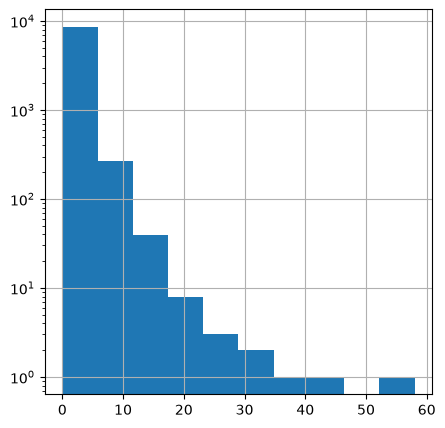

In [7]:
x_train['previous'].hist(bins=10, log=True,figsize=(5,5))

In [8]:
x_train['poutcome'].describe()

count        2240
unique          3
top       failure
freq          974
Name: poutcome, dtype: object

In [9]:
x_train['poutcome'].isna().mean()*100

np.float64(74.91320416620002)

In [10]:
x_train['contact']=x_train['contact'].fillna('no contact')

In [11]:
x_train['poutcome']=x_train['poutcome'].fillna('inprocess')

In [12]:
print(type(x_train_final))
print(x_train_final.columns.tolist()[:8])


<class 'pandas.DataFrame'>
['balance', 'age', 'day', 'duration', 'campaign', 'pdays', 'previous', 'job_blue-collar']


In [13]:
import numpy as np
import pandas as pd
import sklearn
sklearn.set_config(transform_output="pandas")

from sklearn.preprocessing import (OneHotEncoder, StandardScaler, PowerTransformer, MinMaxScaler, FunctionTransformer)
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

age_number_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('transform', FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
    ('scalar', MinMaxScaler())
])

balance_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('transform', PowerTransformer(method='yeo-johnson')),
    ('scalar', StandardScaler())
])

day_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scalar', MinMaxScaler())
])

duration_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('transform', FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
    ('scalar', StandardScaler())
])

campaign_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('transform', FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
    ('scalar', StandardScaler())
])

pdays_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('transform', PowerTransformer(method='yeo-johnson')),
    ('scalar', StandardScaler())
])

prevoius_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('transform', PowerTransformer(method='yeo-johnson')),
    ('scalar', StandardScaler())
])

job_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(sparse_output=False, dtype=int, drop='first'))
])

preprocessor = ColumnTransformer([
    ('balance_pipe', balance_pipe, ['balance']),
    ('age_number_pipe', age_number_pipe, ['age']),
    ('day_pipe', day_pipe, ['day']),
    ('duration_pipe', duration_pipe, ['duration']),
    ('campaign_pipe', campaign_pipe, ['campaign']),
    ('pdays_pipe', pdays_pipe, ['pdays']),
    ('prevoius_pipe', prevoius_pipe, ['previous']),
    ('job_pipe', job_pipe, ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome'])
], remainder='passthrough', verbose_feature_names_out=False) 


x_train_final = preprocessor.fit_transform(x_train)
x_test_final = preprocessor.transform(x_test)


print(x_train_final)

        balance       age       day  duration  campaign     pdays  previous  \
3955   1.440574  0.261037  0.300000  1.688883  1.421915  1.748611  1.830018   
11150 -0.307910  0.377126  0.666667  0.167986  0.579111 -0.578448 -0.577272   
5173  -0.381555  0.584836  0.300000  0.954526 -0.861671  1.683610  1.500969   
3017   0.299080  0.644817  0.466667  0.300758 -0.861671 -0.578448 -0.577272   
2910   0.183543  0.644817  0.333333 -0.540962  0.579111  1.689646  1.882117   
...         ...       ...       ...       ...       ...       ...       ...   
5734  -0.135935  0.572107  0.333333 -1.214966 -0.018868 -0.578448 -0.577272   
5191  -0.403195  0.261037  0.500000  0.601742 -0.018868  1.565486  1.857719   
5390   0.011123  0.394516  0.633333 -0.360050  3.183116 -0.578448 -0.577272   
860   -0.141931  0.621519  0.800000  0.370893  1.421915 -0.578448 -0.577272   
7270  -0.501712  0.302207  0.733333 -0.012443 -0.861671 -0.578448 -0.577272   

       job_blue-collar  job_entrepreneur  job_house

In [14]:
# y_train=y_train.map({'yes':1,
#                      'no':0})

# y_test=y_test.map({'yes':1,
#                      'no':0})

In [ ]:
from sklearn.linear_model import LinearRegression

model=LinearRegression()
y_train=y_train.map({
    'yes':1,
    'no':0
})

y_test=y_test.map({
    'yes':1,
    'no':0
})
model.fit(x_train_final,y_train)

ValueError: Input y contains NaN.

In [36]:
y_train

3955    NaN
11150   NaN
5173    NaN
3017    NaN
2910    NaN
         ..
5734    NaN
5191    NaN
5390    NaN
860     NaN
7270    NaN
Name: deposit, Length: 8929, dtype: float64

,balance,age,day,duration,campaign,pdays,previous,job_blue-collar,job_entrepreneur,job_housemaid,...,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_inprocess,poutcome_other,poutcome_success
5527,-0.142732,0.768695,0.133333,4.924474,-0.861671,-0.578448,-0.577272,0,0,0,...,1,0,0,0,0,0,0,1,0,0
4541,0.184589,0.443928,0.500000,7.709658,2.483721,-0.578448,-0.577272,1,0,0,...,0,1,0,0,0,0,0,1,0,0
1964,1.220943,0.394516,0.433333,6.212542,-0.861671,1.775074,1.500969,1,0,0,...,0,0,0,1,0,0,0,0,0,0
5007,2.111136,0.572107,0.233333,6.973958,-0.018868,-0.578448,-0.577272,1,0,0,...,0,0,0,0,0,0,0,1,0,0
8928,0.130425,0.394516,0.366667,3.845213,0.579111,-0.578448,-0.577272,0,0,0,...,0,0,0,1,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
376,-0.071271,0.559111,0.200000,5.974905,1.421915,-0.578448,-0.577272,0,0,0,...,1,0,0,0,0,0,0,1,0,0
5544,-0.367085,0.597308,0.233333,4.031077,-0.861671,-0.578448,-0.577272,0,0,0,...,0,0,0,1,0,0,0,1,0,0
10749,-0.273808,0.644817,0.133333,3.257897,-0.861671,1.780355,1.500969,0,0,0,...,0,0,0,1,0,0,0,0,0,0
3881,-0.071271,0.584836,0.366667,6.353109,-0.018868,1.740196,1.887715,0,0,0,...,0,0,0,0,0,0,0,0,0,1
